# Практическая работа №1. Линейные дискретные системы и преобразование Фурье

**Вариант 20**

## Цель работы

Изучить математическое описание линейных дискретных систем (ЛДС) и дискретное преобразование Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные понятия

Импульсная характеристика $h(n)$ - реакция ЛДС на единичный импульс $u_0(n)$ при нулевых начальных условиях.

Реакция $y(n)$ на воздействие $x(n)$ равна их свёртке $y(n)=\sum_{i=0}^{n}h(i)x(n-i)$ для причинных последовательностей. 

Передаточная функция $H(z)$ - $z$-преобразование $h(n)$.

Нули — значения $z=z_0$, в которых передаточная функция равна нулю.

Полюса $z=z_*$ определяются корнями её знаменателя после сокращения общих множителей. Все полюса лежат внутри единичного круга.

Амплитудный спектр - модуль фурье-изображения, фазовый спектр - его аргумент. ДПФ сопоставляет $N$ отсчётам $x(n)$ набор из $N$ комплексных отсчётов $X(k)$. Для периодической последовательности $X(k)/N$ задаёт коэффициенты ряда Фурье.

## Постановка задачи

В первой части вычислим импульсную характеристику рекурсивного звена второго порядка и его реакцию двумя способами. Затем найдём нули и полюса, оценим устойчивость и построим АЧХ и ФЧХ. Во второй части исследуем спектр суммы двух гармоник, восстановим периодический аналоговый сигнал и проверим равенство Парсеваля.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N_var = 20

## Часть 1. Рекурсивное звено второго порядка

### 1. Импульсная характеристика

По таблице варианта

| $b_0$ | $b_1$ | $b_2$ | $a_0$ | $a_1$ | $a_2$ | $N_1$ | $N_2$ | $f_{\text{д}}$, Гц |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| $0{,}9$ | $-1{,}20438$ | $0{,}72$ | $1$ | $1{,}2778$ | $0{,}76$ | $20$ | $30$ | $20\,000$ |

$$
H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}
=\frac{0{,}9-1{,}20438z^{-1}+0{,}72z^{-2}}{1+1{,}2778z^{-1}+0{,}76z^{-2}}.
$$

При нулевых начальных условиях:

$$
H(z)=A_0+\frac{A_1}{1-z_{*1}z^{-1}}+\frac{A_2}{1-z_{*2}z^{-1}},
\qquad
h(n)=A_0u_0(n)+A_1z_{*1}^{n}+A_2z_{*2}^{n},\quad n\geq 0.
$$

Здесь $h(n)=0$ при $n<0$, $A_0=b_2/a_2$ и
$$
A_1=\frac{(b_0-A_0)z_{*1}+b_1-A_0a_1}{z_{*1}-z_{*2}},
\qquad A_2=\overline{A_1},
$$
Численно для $n\geq 0$

$$
h(n)\approx 0{,}947368\,u_0(n)
+2\operatorname{Re}\!\left[(-0{,}023684+2{,}010227j)
(-0{,}638900+0{,}593133j)^n\right].
$$

У звена есть несокращаемые полюса, поэтому импульсная характеристика бесконечна. На графике показаны первые $N_1=20$ отсчётов (ответ на то, что в действительности ИХ)

Первые четыре отсчёта h(n): [ 0.9      -2.3544    3.044452 -2.100857]


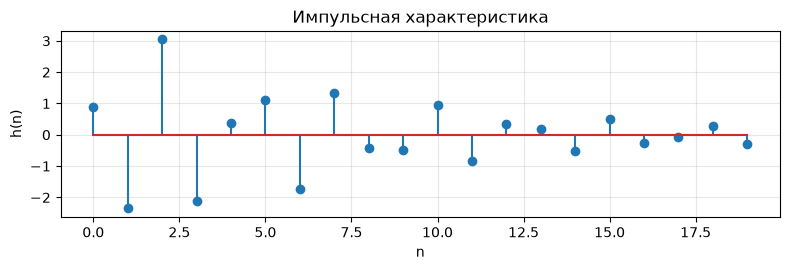

In [2]:
b0 = 0.5 + 0.02 * N_var
b1 = b0 * (-1)**(N_var + 1) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))
a1 = (-1)**N_var * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var

N1 = N_var % 10 + 20
N2 = N_var % 10 + 30
f_d = 1000 * N_var

poles = np.roots([1, a1, a2])
A0 = b2 / a2
A1 = ((b0 - A0) * poles[0] + b1 - A0 * a1) / (poles[0] - poles[1])

n_h = np.arange(N1)
h = 2 * np.real(A1 * poles[0]**n_h)
h[0] += A0

print("Первые четыре отсчёта h(n):", np.round(h[:4], 6))
plt.figure(figsize=(8, 2.8))
plt.stem(n_h, h)
plt.title("Импульсная характеристика")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2. Реакция по формуле свёртки

a) В массиве $x(n)$ содержится $N_2=30$ отсчётов. Длительность прямоугольного импульса составляет $\operatorname{int}(N_2/2)=15$ отсчётов. 

b) При свёртке двух массивов длины $N_2=30$ и $N_1=20$ получается $N_2+N_1-1=49$ отсчётов, $0\leq n\leq48$. На графике ненулевая часть занимает диапазон до $n=33$ включительно, а дальше нули.

c) Для сравнения с реакцией по разностному уравнению берём общую сетку из $N_2=30$ отсчётов. За её пределами причинная система продолжает реагировать на уже завершившийся импульс.

Длина массива свёртки: 49
Последний ненулевой отсчёт свёртки: 33


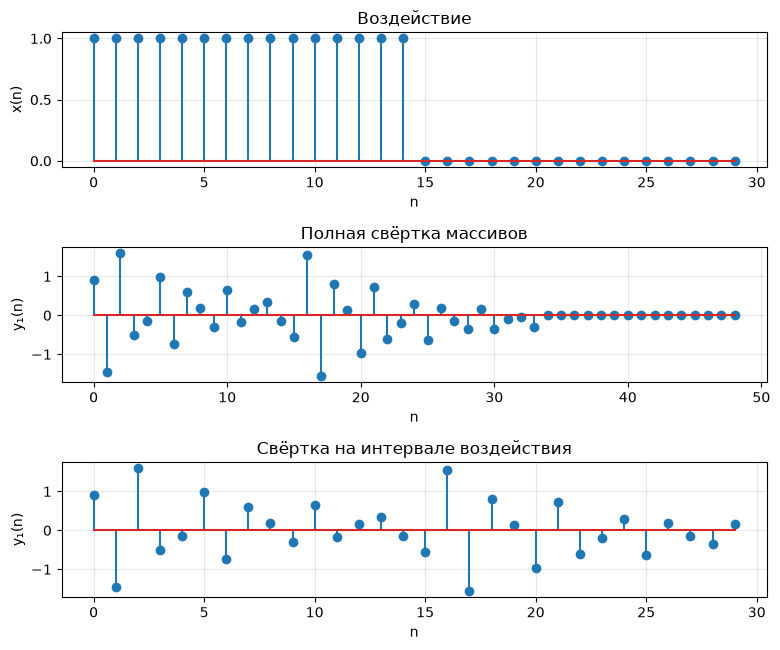

In [3]:
n_x = np.arange(N2)
width = round(N2 / 2)
x = np.zeros(N2)
x[:width] = 1

y1_full = np.convolve(x, h)
y1 = y1_full[:N2]

print("Длина массива свёртки:", len(y1_full))
print("Последний ненулевой отсчёт свёртки:", np.flatnonzero(y1_full)[-1])

fig, ax = plt.subplots(3, 1, figsize=(8, 6.6))
ax[0].stem(n_x, x)
ax[0].set_ylabel("x(n)")
ax[0].set_title("Воздействие")
ax[1].stem(np.arange(len(y1_full)), y1_full)
ax[1].set_ylabel("y₁(n)")
ax[1].set_title("Полная свёртка массивов")
ax[2].stem(n_x, y1)
ax[2].set_ylabel("y₁(n)")
ax[2].set_title("Свёртка на интервале воздействия")
for axis in ax:
    axis.set_xlabel("n")
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 3. Реакция по разностному уравнению

$$
\begin{aligned}
y_2(n)={}&0{,}9x(n)-1{,}20438x(n-1)+0{,}72x(n-2)\\
&-1{,}2778y_2(n-1)-0{,}76y_2(n-2).
\end{aligned}
$$

До начала воздействия $x(n)=y_2(n)=0$. Воздействие задано массивом длины $30$, а реакцию вычисляем на тех же $30$ индексах. Полная реакция бесконечна.

Ну те
- Воздействие задано массивом длины N₂=30 отсчётов: первые 15 единицы, остальные нули
- Реакция рассчитана на 30 отсчётах. В действительности её длина бесконечна: после окончания импульса обратная связь поддерживает затухающие колебания

Макс. |y₁ − y₂| при n < 20: 1.22e-15
Макс. |y₁ − y₂| на всех 30 отсчётах: 0.213578
Макс. ошибка свёртки с 30 отсчётами h(n): 7.77e-16


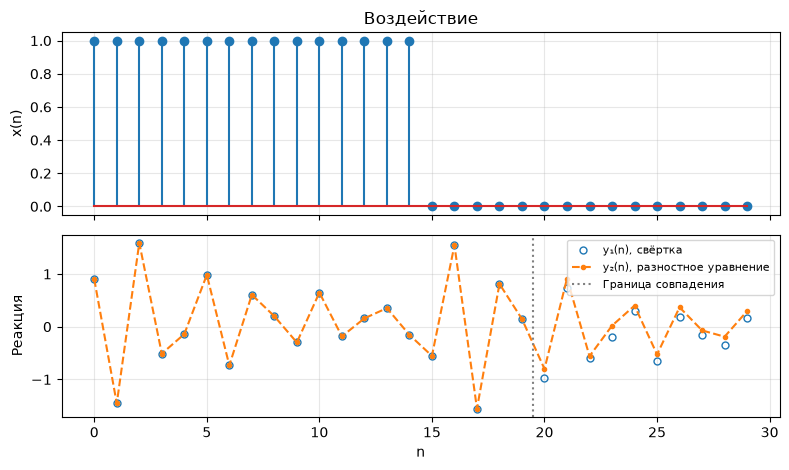

In [4]:
def response(x, b0, b1, b2, a1, a2):
    x_padded = np.pad(x, (2, 0))
    y = np.zeros(len(x_padded))
    for n in range(2, len(x_padded)):
        y[n] = (
            b0 * x_padded[n] + b1 * x_padded[n - 1] + b2 * x_padded[n - 2]
            - a1 * y[n - 1] - a2 * y[n - 2]
        )
    return y[2:]


y2 = response(x, b0, b1, b2, a1, a2)

u0 = np.zeros(N2)
u0[0] = 1
h_long = response(u0, b0, b1, b2, a1, a2)
y1_long = np.convolve(x, h_long)[:N2]

assert np.allclose(h, h_long[:N1])
assert np.allclose(y1[:N1], y2[:N1])
assert np.allclose(y1_long, y2)
print(f"Макс. |y₁ − y₂| при n < {N1}: {np.max(np.abs(y1[:N1] - y2[:N1])):.2e}")
print(f"Макс. |y₁ − y₂| на всех {N2} отсчётах: {np.max(np.abs(y1 - y2)):.6f}")
print(f"Макс. ошибка свёртки с {N2} отсчётами h(n): {np.max(np.abs(y1_long - y2)):.2e}")

fig, ax = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
ax[0].stem(n_x, x)
ax[0].set_ylabel("x(n)")
ax[0].set_title("Воздействие")
ax[1].plot(n_x, y1, "o", ms=5, fillstyle="none", label="y₁(n), свёртка")
ax[1].plot(n_x, y2, ".--", label="y₂(n), разностное уравнение")
ax[1].axvline(N1 - 0.5, color="gray", ls=":", label="Граница совпадения")
ax[1].set_xlabel("n")
ax[1].set_ylabel("Реакция")
ax[1].legend(fontsize=8)
for axis in ax:
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Реакции совпадают при $n<20$; далее возникает ошибка усечения $h(n)$. При длине $h(n)=30$ отсчётов совпадение сохраняется на всём интервале сравнения.

### 4. Нули и полюса передаточной функции

Умножаем числитель и знаменатель $H(z)$ на $z^2$. Нули находим из $b_0z^2+b_1z+b_2=0$, полюса из $z^2+a_1z+a_2=0$. Переход от алгебраической записи к показательной задаётся равенством $z=\xi+j\eta=r e^{j\varphi}$, где $r=\sqrt{\xi^2+\eta^2}$, $\varphi=\arg z$.

| Точки | Алгебраическая форма | Показательная форма | $\varphi/\pi$ |
|---|---|---|---:|
| $z_{01,02}$ | $0{,}669100\pm0{,}593553j$ | $0{,}894427\,e^{\pm j\,0{,}230978\pi}$ | $\pm0{,}230978$ |
| $z_{*1,*2}$ | $-0{,}638900\pm0{,}593133j$ | $0{,}871780\,e^{\pm j\,0{,}761819\pi}$ | $\pm0{,}761819$ |

$$
H(z)\approx 0{,}9\,
\frac{
(1-0{,}894427e^{j\,0{,}230978\pi}z^{-1})
(1-0{,}894427e^{-j\,0{,}230978\pi}z^{-1})
}{
(1-0{,}871780e^{j\,0{,}761819\pi}z^{-1})
(1-0{,}871780e^{-j\,0{,}761819\pi}z^{-1})
}.
$$

In [4]:
zeros = np.roots([b0, b1, b2])
for name, points in [("Нули", zeros), ("Полюса", poles)]:
    print(name)
    for point in points:
        print(f"  {point:.5f}, модуль = {abs(point):.6f}, аргумент/π = {np.angle(point)/np.pi:.6f}")

Нули
  0.66910+0.59355j, модуль = 0.894427, аргумент/π = 0.230978
  0.66910-0.59355j, модуль = 0.894427, аргумент/π = -0.230978
Полюса
  -0.63890+0.59313j, модуль = 0.871780, аргумент/π = 0.761819
  -0.63890-0.59313j, модуль = 0.871780, аргумент/π = -0.761819


### 5. Карта нулей и полюсов

Координаты маркеров совпадают со значениями из п. 4.

1. Звено устойчиво, поскольку оба полюса находятся внутри единичной окружности:
   $|z_{*1}|=|z_{*2}|=√(0,76)≈0,872<1.$
   Поэтому свободные колебания затухают, а ограниченное воздействие вызывает ограниченную реакцию.
2. Значения совпадают с пунктом 4: на карте изображены те же вычисленные корни. Горизонтальная ось - это действительная часть, вертикальная - это мнимая:
   - нули: 0,6691± j0,5936;
   - полюса: -0,6389± j0,5931.

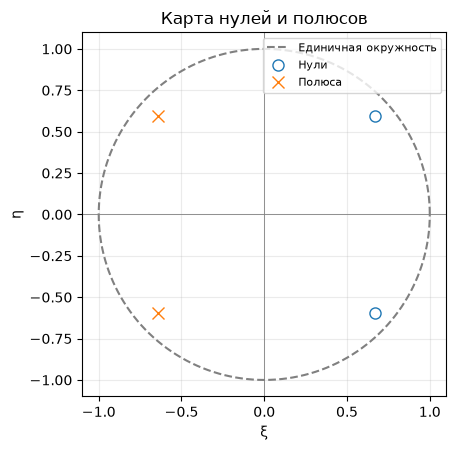

In [6]:
angle = np.linspace(0, 2 * np.pi, 361)
plt.figure(figsize=(5.5, 4.6))
plt.plot(np.cos(angle), np.sin(angle), "--", color="gray", label="Единичная окружность")
plt.plot(zeros.real, zeros.imag, "o", ms=8, fillstyle="none", label="Нули")
plt.plot(poles.real, poles.imag, "x", ms=8, label="Полюса")
plt.axhline(0, color="gray", lw=0.6)
plt.axvline(0, color="gray", lw=0.6)
plt.gca().set_aspect("equal")
plt.xlabel("ξ")
plt.ylabel("η")
plt.title("Карта нулей и полюсов")
plt.legend(loc="upper right", fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Пункт 6

a. Основная полоса нормированных частот: $-\pi \leq \hat\omega < \pi$. АЧХ и ФЧХ периодичны с периодом $2\pi$.

b. Вблизи углов нулей наблюдаются провалы АЧХ, вблизи углов полюсов - это пики. Минимумы расположены около $\hat\omega = \pm 0{,}227\pi$, максимумы около $\pm 0{,}768\pi$.

c. Скачка ФЧХ на $\pi$ в данном варианте нет. При прохождении частотной характеристики через нуль такой скачок соответствовал бы нулевому значению АЧХ.

d. Преимущественно подавлены низкочастотные составляющие воздействия: при $\hat\omega = 0$ АЧХ равна примерно $0{,}137$. Высокочастотные составляющие вблизи пиков усиливаются.

### Пункт 7

a. При частоте дискретизации $f_{\text{д}} = 20\,000$ Гц основная полоса частот: $-10\,000 \leq f < 10\,000$ Гц.

b. Нормированная и абсолютная частоты связаны соотношениями:

$$
\hat\omega = \frac{2\pi f}{f_{\text{д}}},
\qquad
f = \frac{\hat\omega f_{\text{д}}}{2\pi}.
$$

Значению $\hat\omega = \pi$ соответствует $f = 10\,000$ Гц. При смене частотной шкалы форма АЧХ и ФЧХ сохраняется.

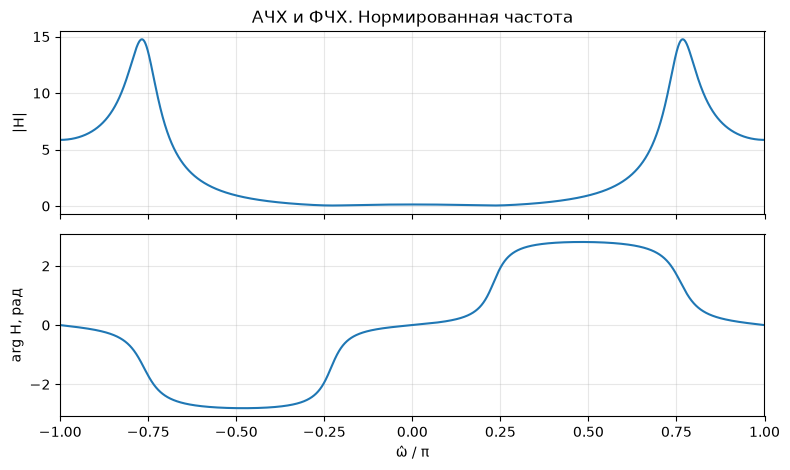

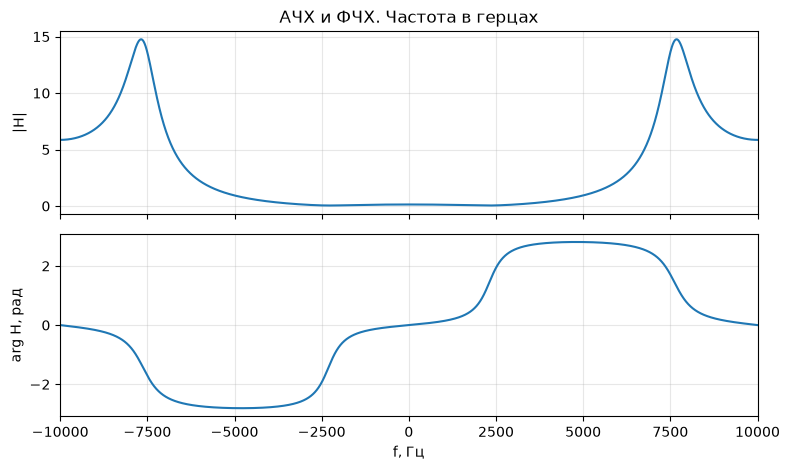

Минимум АЧХ при ω̂/π ≈ 0.227
Максимум АЧХ при ω̂/π ≈ 0.768
АЧХ при ω̂ = 0: 0.137
АЧХ при ω̂ = π: 5.857
Скачки фазы на сетке: 0


In [7]:
omega_hat = np.linspace(-np.pi, np.pi, 4097)
f = omega_hat * f_d / (2 * np.pi)
z_inv = np.exp(-1j * omega_hat)
H = (b0 + b1 * z_inv + b2 * z_inv**2) / (1 + a1 * z_inv + a2 * z_inv**2)
amplitude = np.abs(H)
phase = np.angle(H)

for frequencies, label, title in [
    (omega_hat / np.pi, "ω̂ / π", "Нормированная частота"),
    (f, "f, Гц", "Частота в герцах"),
]:
    fig, ax = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
    ax[0].plot(frequencies, amplitude)
    ax[0].set_ylabel("|H|")
    ax[0].set_title("АЧХ и ФЧХ. " + title)
    ax[1].plot(frequencies, phase)
    ax[1].set_ylabel("arg H, рад")
    ax[1].set_xlabel(label)
    for axis in ax:
        axis.grid(alpha=0.3)
        axis.set_xlim(frequencies[0], frequencies[-1])
    fig.tight_layout()
    plt.show()

positive = omega_hat >= 0
w_positive = omega_hat[positive] / np.pi
print(f"Минимум АЧХ при ω̂/π ≈ {w_positive[np.argmin(amplitude[positive])]:.3f}")
print(f"Максимум АЧХ при ω̂/π ≈ {w_positive[np.argmax(amplitude[positive])]:.3f}")
print(f"АЧХ при ω̂ = 0: {amplitude[len(omega_hat) // 2]:.3f}")
print(f"АЧХ при ω̂ = π: {amplitude[-1]:.3f}")
print(f"Скачки фазы на сетке: {np.count_nonzero(np.abs(np.diff(phase)) > np.pi)}")

## Часть 2. Дискретное преобразование Фурье

### 1. Последовательность на одном периоде

По таблице варианта $N=64$, $f_{\text{д}}=2000$ Гц, $T=0{,}0005$ с, $A_1=1{,}2$, $A_2=2{,}4$, $f_1=250$ Гц и $f_2=375$ Гц.

$$
x(nT)=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8).
$$

Дискретное время - $nT$ в секундах, нормированное время - $n=(nT)/T$ в отсчётах.

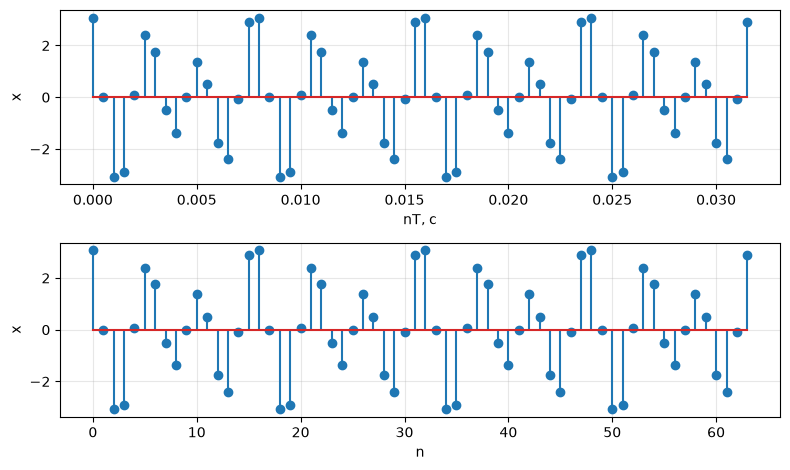

In [8]:
N = 64
f_d = 2000 * (N_var % 5 + 1)
T = 1 / f_d
A1 = 1 + 0.01 * N_var
A2 = 2 * A1
f1 = f_d / 8
f2 = 1.5 * f1

n = np.arange(N)
t_samples = n * T
x = A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4)
x += A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8)

fig, ax = plt.subplots(2, 1, figsize=(8, 4.8))
ax[0].stem(t_samples, x)
ax[0].set_xlabel("nT, с")
ax[1].stem(n, x)
ax[1].set_xlabel("n")
for axis in ax:
    axis.set_ylabel("x")
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 2. ОДПФ от ДПФ

Используем соглашение, при котором множитель $1/N$ входит в обратное преобразование.
$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N},
\qquad
x(n)=\frac{1}{N}\sum_{k=0}^{N-1}X(k)e^{j2\pi kn/N}.
$$

Максимальная ошибка ОДПФ: 1.34e-15


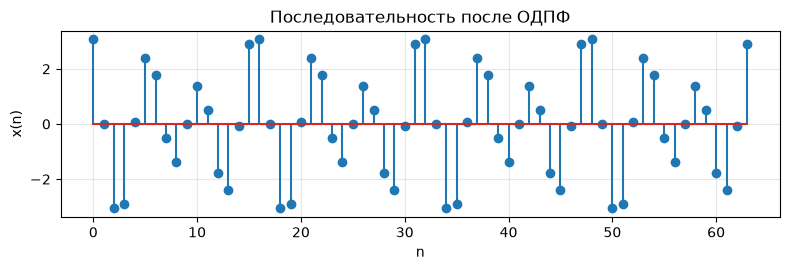

In [9]:
X = np.fft.fft(x)
x_idft = np.fft.ifft(X)
assert np.allclose(x_idft, x)
print(f"Максимальная ошибка ОДПФ: {np.max(np.abs(x_idft - x)):.2e}")

plt.figure(figsize=(8, 2.8))
plt.stem(n, x_idft.real)
plt.xlabel("n")
plt.ylabel("x(n)")
plt.title("Последовательность после ОДПФ")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Амплитудный и фазовый спектры

a. Дискретное время равно $t_n=nT$ и измеряется в секундах. Дискретное нормированное время - номер отсчёта $n=t_n/T$, где $T=1/f_{\text{д}}=0{,}0005$ с.

b. Частота в герцах связана с дискретной нормированной частотой соотношением:

$$
\hat\omega_k=\frac{2\pi f_k}{f_{\text{д}}},
\qquad
f_k=\frac{k f_{\text{д}}}{N}.
$$

При $f_{\text{д}}=2000$ Гц частотам $250$ и $375$ Гц соответствуют $\hat\omega=\pi/4$ и $3\pi/8$.

c. Амплитудный спектр содержит четыре линии: при $f=\pm250$ Гц с амплитудой $0{,}6$ и при $f=\pm375$ Гц с амплитудой $1{,}2$. Каждая косинусоида даёт две линии с половиной её амплитуды.Фазы при положительных частотах равны $\pi/4$ и $\pi/8$, при отрицательных $-\pi/4$ и $-\pi/8$. Амплитудный спектр чётный, фазовый нечётный; фаза нулевых спектральных составляющих не определена.

  k      f, Гц    |Xₐ(k)|/N    Фаза/π
-12    -375.00     1.200000  -0.125000
 -8    -250.00     0.600000  -0.250000
  8     250.00     0.600000   0.250000
 12     375.00     1.200000   0.125000


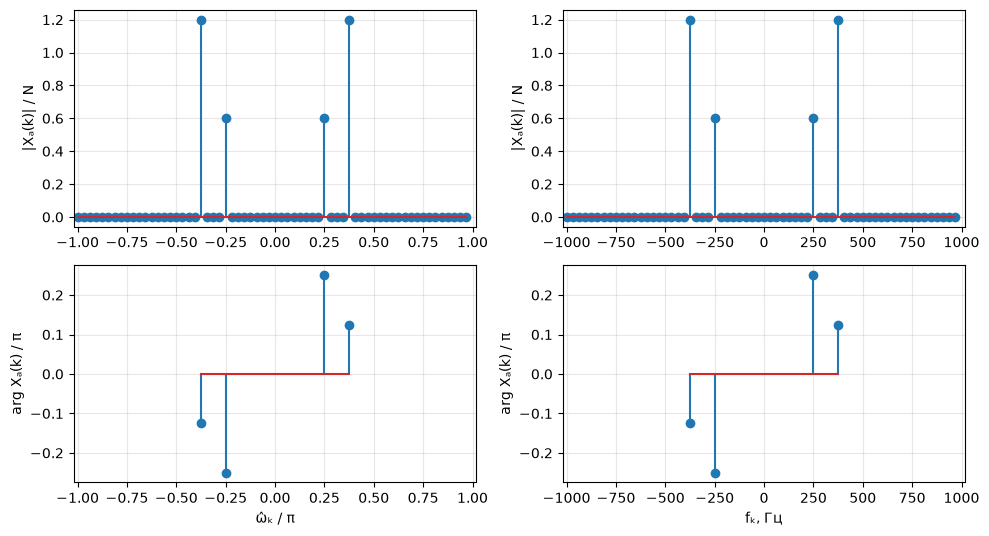

In [10]:
k = np.arange(-N // 2, N // 2)
omega_hat_k = 2 * np.pi * k / N
f_k = k / (N * T)
X_a = np.fft.fftshift(X)
amplitude_periodic = np.abs(X_a) / N
phase_periodic = np.angle(X_a)
lines = amplitude_periodic > 1e-10

print("  k      f, Гц    |Xₐ(k)|/N    Фаза/π")
for index in np.flatnonzero(lines):
    print(f"{k[index]:3d} {f_k[index]:10.2f} {amplitude_periodic[index]:12.6f}"
          f" {phase_periodic[index] / np.pi:10.6f}")

fig, ax = plt.subplots(2, 2, figsize=(10, 5.5))
for col, (frequencies, label) in enumerate([(omega_hat_k / np.pi, "ω̂ₖ / π"), (f_k, "fₖ, Гц")]):
    ax[0, col].stem(frequencies, amplitude_periodic)
    ax[0, col].set_ylabel("|Xₐ(k)| / N")
    ax[1, col].stem(frequencies[lines], phase_periodic[lines] / np.pi)
    ax[1, col].set_ylabel("arg Xₐ(k) / π")
    ax[1, col].set_xlabel(label)
    for axis in ax[:, col]:
        axis.set_xlim(-1.02 * abs(frequencies[0]), 1.02 * abs(frequencies[0]))
        axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 4. ДПФ конечной последовательности и спектр периодической последовательности

Амплитудный спектр периодической последовательности равен модулю ДПФ конечного блока, делённому на $N$. Поэтому линии на обоих графиках расположены на одинаковых частотах, а высоты равны соответственно $38{,}4$ и $76{,}8$ для конечного блока и $0{,}6$ и $1{,}2$ для периодического сигнала.

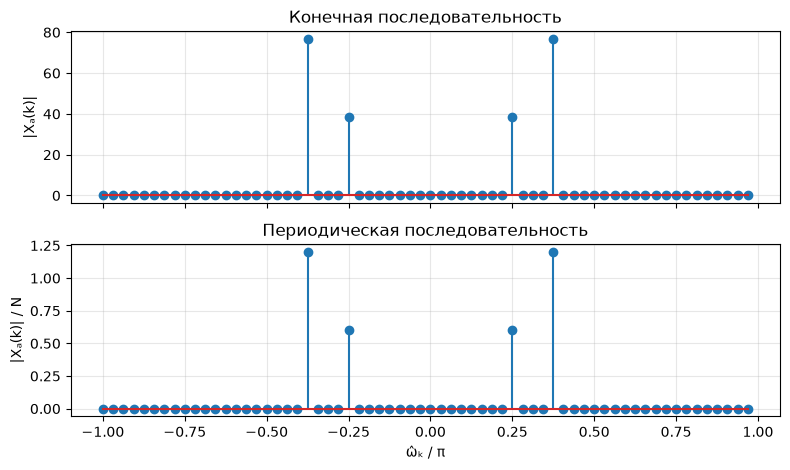

In [11]:
X_finite = np.fft.fft(x[:N], n=N)
mod_dft = np.abs(np.fft.fftshift(X_finite))
assert np.allclose(mod_dft, N * amplitude_periodic)

fig, ax = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
ax[0].stem(omega_hat_k / np.pi, mod_dft)
ax[0].set_title("Конечная последовательность")
ax[0].set_ylabel("|Xₐ(k)|")
ax[1].stem(omega_hat_k / np.pi, amplitude_periodic)
ax[1].set_title("Периодическая последовательность")
ax[1].set_ylabel("|Xₐ(k)| / N")
ax[1].set_xlabel("ω̂ₖ / π")
for axis in ax:
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 5–6. Восстановление и сравнение аналоговых сигналов

Суммируем гармоники по формуле задания:
$$
x(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_{\text{а}}(k)
\exp\!\left(j\frac{2\pi}{NT}kt\right),
\qquad
X_{\text{а}}(k)=
\begin{cases}
X(N+k),& -N/2\leq k\leq -1,\\
X(k),&0\leq k\leq N/2-1.
\end{cases}
$$

Сетка восстановления имеет шаг $0{,}25T$ и включает точки $0$ и $(N-1)T$.

### 5 

a. Периодическая последовательность содержит $N=64$ отсчёта. Модуль её ДПФ имеет линии при $f=\pm250$ Гц и $f=\pm375$ Гц высотой $38{,}4$ и $76{,}8$ соответственно.

b. Аналоговый сигнал восстановлен по отсчётам ДПФ на интервале $[0;0{,}0315]$ с шагом $\Delta t=0{,}000125$ с. Его амплитудный спектр содержит линии при $f=\pm250$ Гц высотой $0{,}6$ и при $f=\pm375$ Гц высотой $1{,}2$.

c. Исходный аналоговый сигнал построен подстановкой непрерывного времени $t$ вместо $nT$:

$$
x(t)=1{,}2\cos(2\pi\cdot250t+\pi/4)
+2{,}4\cos(2\pi\cdot375t+\pi/8).
$$

### 6
a. Амплитудный спектр аналогового сигнала равен модулю ДПФ, делённому на $N=64$: $|X_{\text{а}}(k)|/N$. Частоты соответствующих линий совпадают.

b. Восстановленный и исходный сигналы визуально совпадают, в том числе между отсчётами. Частоты гармоник ниже частоты Найквиста $1000$ Гц и попадают на сетку ДПФ. Ошибка восстановления составляет около $3{,}5\cdot10^{-14}$.

Максимальная ошибка восстановления на всей сетке: 3.46e-14


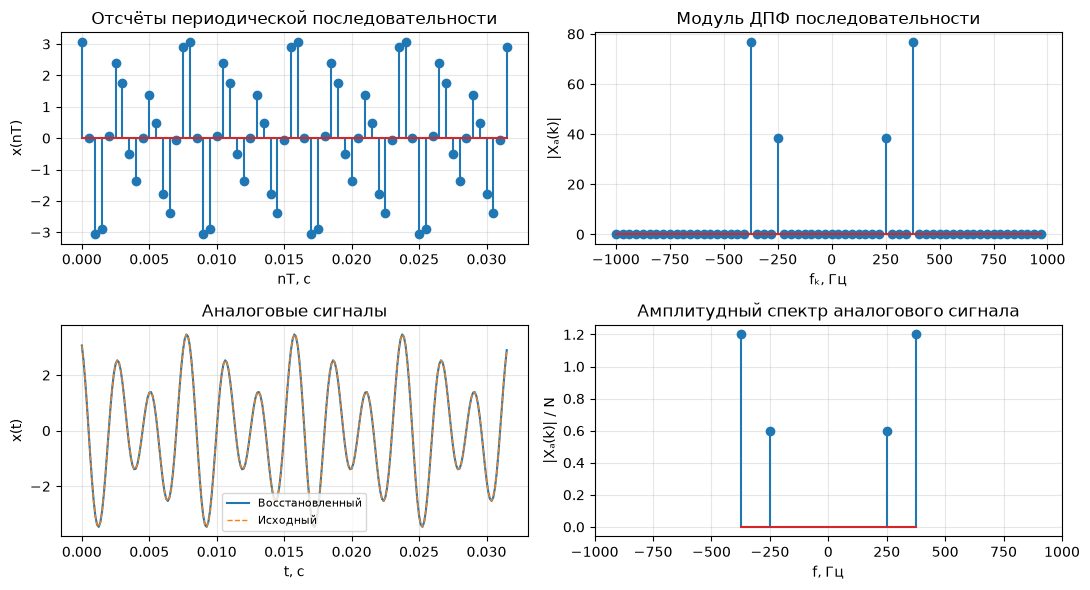

In [12]:
t = np.arange(4 * (N - 1) + 1) * T / 4
x_restored = np.zeros(len(t), dtype=complex)
for index in range(N):
    x_restored += X_a[index] * np.exp(1j * 2 * np.pi * k[index] * t / (N * T))
x_restored /= N

x_original = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4)
x_original += A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

assert np.allclose(x_restored[::4], x)
assert np.allclose(x_restored, x_original)
print(f"Максимальная ошибка восстановления на всей сетке: {np.max(np.abs(x_restored - x_original)):.2e}")

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
ax[0, 0].stem(t_samples, x)
ax[0, 0].set_title("Отсчёты периодической последовательности")
ax[0, 0].set_xlabel("nT, с")
ax[0, 0].set_ylabel("x(nT)")
ax[0, 1].stem(f_k, np.abs(X_a))
ax[0, 1].set_title("Модуль ДПФ последовательности")
ax[0, 1].set_xlabel("fₖ, Гц")
ax[0, 1].set_ylabel("|Xₐ(k)|")
ax[1, 0].plot(t, x_restored.real, label="Восстановленный")
ax[1, 0].plot(t, x_original, "--", lw=1, label="Исходный")
ax[1, 0].set_title("Аналоговые сигналы")
ax[1, 0].set_xlabel("t, с")
ax[1, 0].set_ylabel("x(t)")
ax[1, 0].legend(fontsize=8)
ax[1, 1].stem(f_k[lines], amplitude_periodic[lines])
ax[1, 1].set_xlim(-f_d / 2, f_d / 2)
ax[1, 1].set_title("Амплитудный спектр аналогового сигнала")
ax[1, 1].set_xlabel("f, Гц")
ax[1, 1].set_ylabel("|Xₐ(k)| / N")
for axis in ax.flat:
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 7. Равенство Парсеваля

Равенство Парсеваля связывает энергию последовательности с энергией её частотного представления:

$$
\sum_{n=0}^{N-1}|x(n)|^2
=
\frac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2.
$$

Левая часть вычисляется по отсчётам сигнала, правая по коэффициентам его ДПФ. Множитель $1/N$ связан с принятой нормировкой преобразования. Смысл равенства заключается в том, что переход от временного представления к частотному сохраняет энергию: ДПФ показывает, как она распределена между частотными составляющими.

В работе обе части равны $230{,}4$, следовательно, равенство Парсеваля выполняется с точностью вычислений. Для периодической последовательности это энергия блока из $N=64$ отсчётов. Средняя мощность равна:

$$
P=\frac{1}{N}\sum_{n=0}^{N-1}|x(n)|^2
=\frac{230{,}4}{64}=3{,}6.
$$

Она также совпадает с суммой средних мощностей двух гармоник:

$$
P=\frac{A_1^2}{2}+\frac{A_2^2}{2}
=\frac{1{,}2^2}{2}+\frac{2{,}4^2}{2}=3{,}6.
$$


In [13]:
energy_time = np.sum(np.abs(x)**2)
energy_frequency = np.sum(np.abs(X)**2) / N
assert np.isclose(energy_time, energy_frequency)
print(f"Энергия блока во времени: {energy_time:.6f}")
print(f"Энергия блока по ДПФ:      {energy_frequency:.6f}")
print(f"Средняя мощность:         {energy_time / N:.6f}")

Энергия блока во времени: 230.400000
Энергия блока по ДПФ:      230.400000
Средняя мощность:         3.600000


## Общие выводы

### 1. Линейная дискретная система

Получена аналитическая формула импульсной характеристики рекурсивного звена второго порядка. Её действительная длина бесконечна, а отсчёты затухают. Реакции, рассчитанные через свёртку и по разностному уравнению, совпадают при достаточной длине импульсной характеристики. Расхождение при её усечении до 20 отсчётов объясняется потерей части отклика.

Вычислены нули и полюса передаточной функции. Полюса находятся внутри единичной окружности, поэтому звено устойчиво. Провалы АЧХ соответствуют углам нулей, пики — углам полюсов. Звено преимущественно подавляет низкочастотные составляющие и усиливает составляющие вблизи высокочастотных пиков.

### 2. Дискретное преобразование Фурье

ДПФ выявило гармоники на частотах 250 и 375 Гц с амплитудами и фазами, соответствующими исходному сигналу. Амплитудный спектр периодического сигнала равен модулю ДПФ конечного блока, делённому на $N$.

Обратное ДПФ вернуло исходные отсчёты, а восстановленный аналоговый сигнал совпал с исходным, включая точки между отсчётами. Равенство Парсеваля подтвердило сохранение энергии при переходе к частотному представлению: энергия блока равна $230{,}4$, средняя мощность $3{,}6$.
